# 04 – Détection d'anomalies : repérer la dégradation avant la panne

**Objectif :** détecter qu'une machine **s'écarte de son comportement normal**, sans avoir besoin d'étiquettes « panne ».

**Idée :** on entraîne chaque modèle **uniquement sur des mesures saines** (le début de vie après une maintenance). Plus une mesure ressemble peu à ce qu'il a vu, plus son **score d'anomalie** est élevé.

**Entrée :** `data/processed/features_temporal.csv` (créé par `src/features.py`).
**Sorties :** `reports/tables/resultats_anomalies.csv`, `reports/figures/anomalies_*.png`.

**Modèles comparés :** Isolation Forest, One-Class SVM, autoencodeur (réseau qui apprend à reconstruire les données saines).

Données **synthétiques** : les résultats montrent que la méthode fonctionne sur un cas simulé, pas sur une vraie usine.

In [8]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "features.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from features import split_by_machine, SENSOR_COLS
(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
(ROOT / "reports/tables").mkdir(parents=True, exist_ok=True)
SEED = 42

## 1. Chargement et choix des variables

In [10]:
df = pd.read_csv(ROOT / "data/processed/features_temporal.csv")

# variables d'entrée = capteurs + features glissantes (on exclut age_h, time_h, rul_h et les étiquettes
FEATURES = [c for c in df.columns if any(c.startswith(s) for s in SENSOR_COLS)]
print(len(FEATURES), "variables :", FEATURES[:6], "...")
print(df.shape)

30 variables : ['vib_rms', 'vib_kurtosis', 'vib_crest', 'temperature', 'pressure', 'current'] ...
(78836, 38)


## 2. Données saines pour l'entraînement

On ne connaît pas l'état réel de la machine. On suppose, comme en usine, que **les 300 premières heures après une maintenance sont saines**.

Le découpage se fait **par machine** (jamais au hasard sur les lignes) :
- `fit` : machines pour entraîner (sur leurs mesures saines),
- `cal` : machines pour calibrer le **seuil d'alarme** (sur leurs mesures saines),
- `test` : machines jamais vues, pour évaluer.

In [12]:
HEALTHY_H = 300   # heures considérées comme saines après une maintenance

train, test = split_by_machine(df, test_size=0.25, seed=SEED)
fit, cal = split_by_machine(train, test_size=0.2, seed=SEED)
print("machines  fit / cal / test :", fit.machine_id.nunique(), cal.machine_id.nunique(), test.machine_id.nunique())

X_fit = fit.loc[fit.age_h < HEALTHY_H, FEATURES]
scaler = StandardScaler().fit(X_fit)
X_fit_s = scaler.transform(X_fit)
print("mesures saines pour l'entraînement :", X_fit_s.shape)

machines  fit / cal / test : 36 9 15
mesures saines pour l'entraînement : (6356, 30)


## 3. Entraînement des trois modèles

In [13]:
rng = np.random.default_rng(SEED)
models = {}

models["Isolation Forest"] = IsolationForest(n_estimators=200, random_state=SEED).fit(X_fit_s)

# One-Class SVM est lent : on l'entraîne sur un échantillon de 5000 mesures saines
sub = rng.choice(len(X_fit_s), size=min(5000, len(X_fit_s)), replace=False)
models["One-Class SVM"] = OneClassSVM(nu=0.05, gamma="scale").fit(X_fit_s[sub])

# Autoencodeur : un réseau qui apprend à reconstruire les mesures saines.
# Sur une mesure dégradée, il reconstruit mal -> l'erreur de reconstruction = le score d'anomalie.
models["Autoencodeur"] = MLPRegressor(hidden_layer_sizes=(16, 6, 16), max_iter=300,
                                      random_state=SEED).fit(X_fit_s, X_fit_s)

def anomaly_score(name, X):
    """Score d'anomalie : PLUS IL EST GRAND, PLUS LA MESURE EST ANORMALE."""
    Xs = scaler.transform(X)
    m = models[name]
    if name == "Autoencodeur":
        return ((m.predict(Xs) - Xs) ** 2).mean(axis=1)
    return -m.score_samples(Xs)

test = test.copy()
cal = cal.copy()
for name in models:
    test[f"score_{name}"] = anomaly_score(name, test[FEATURES])
    cal[f"score_{name}"] = anomaly_score(name, cal[FEATURES])
print("scores calculés")

scores calculés


## 4. Les scores montent-ils quand la machine se dégrade ?

L'indicateur de santé `age / durée de vie` (0 = neuf, 1 = panne) sert **uniquement à l'évaluation** : aucun modèle ne l'a vu. On le calcule seulement sur les cycles qui se terminent par une panne (sinon la durée de vie est inconnue).

In [14]:
t = test.dropna(subset=["rul_h"]).copy()
t["sante"] = t.age_h / (t.age_h + t.rul_h)
t["phase"] = pd.cut(t.sante, [-0.01, 0.5, 0.75, 0.9, 1.0],
                    labels=["0-50 %", "50-75 %", "75-90 %", "90-100 %"])
score_cols = [f"score_{n}" for n in models]
print(t.groupby("phase", observed=True)[score_cols].median().round(3))

          score_Isolation Forest  score_One-Class SVM  score_Autoencodeur
phase                                                                    
0-50 %                     0.440              -10.782               0.266
50-75 %                    0.601               -2.461               1.335
75-90 %                    0.672               -0.095               4.947
90-100 %                   0.692               -0.000              10.125


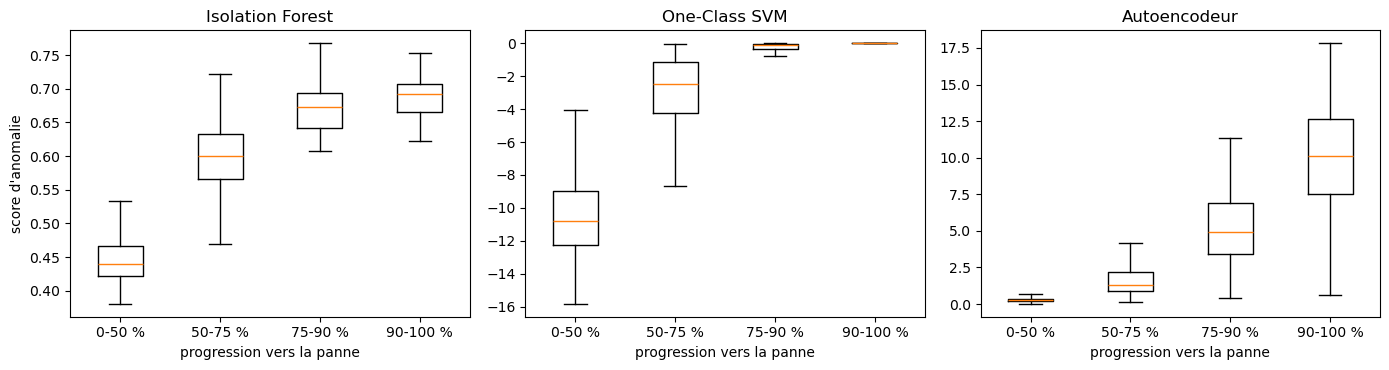

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, n in zip(axes, models):
    data = [t.loc[t.phase == p, f"score_{n}"] for p in t.phase.cat.categories]
    ax.boxplot(data, showfliers=False)
    ax.set_xticklabels(list(t.phase.cat.categories))
    ax.set_title(n); ax.set_xlabel("progression vers la panne")
axes[0].set_ylabel("score d'anomalie")
plt.tight_layout()
plt.savefig(ROOT / "reports/figures/anomalies_scores_par_phase.png", dpi=150)
plt.show()

## 5. Évaluation : détecter « panne dans les 48 h »

On compare le score à l'étiquette `failure_within_h` (jamais utilisée à l'entraînement). **ROC-AUC** et surtout **PR-AUC** (classes très déséquilibrées : ~1,7 % de positifs).

Taux de positifs dans le test : 1.79%  (PR-AUC d'un modèle au hasard ≈ ce taux)



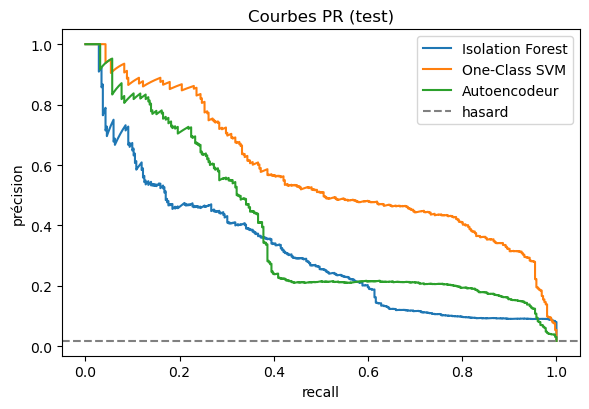

,ROC-AUC,PR-AUC
modèle,,
Isolation Forest,0.941,0.314
One-Class SVM,0.983,0.576
Autoencodeur,0.955,0.391


In [16]:
y = test["failure_within_h"]
print(f"Taux de positifs dans le test : {y.mean():.2%}  (PR-AUC d'un modèle au hasard ≈ ce taux)\n")
rows = []
plt.figure(figsize=(6, 4.2))
for n in models:
    s = test[f"score_{n}"]
    p, r, _ = precision_recall_curve(y, s)
    plt.plot(r, p, label=n)
    rows.append({"modèle": n, "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s)})
plt.axhline(y.mean(), color="gray", ls="--", label="hasard")
plt.xlabel("recall"); plt.ylabel("précision"); plt.legend(); plt.title("Courbes PR (test)")
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/anomalies_pr_curves.png", dpi=150); plt.show()
res = pd.DataFrame(rows).set_index("modèle").round(3)
res

## 6. Cas d'usage réel : alarme et délai d'anticipation

En usine, on ne regarde pas un AUC : on fixe un **seuil**. Ici : le **99ᵉ percentile** des scores sur des mesures saines de machines `cal` (donc seulement 1 % de fausses alarmes sur du sain). Pour éviter les alarmes isolées, l'alarme ne sonne qu'après **3 mesures consécutives** au-dessus du seuil (18 h).

On mesure :
- **taux de détection** : part des pannes (test) précédées d'une alarme,
- **délai d'anticipation** : heures entre la 1ʳᵉ alarme et la panne,
- **fausses alarmes** : part des mesures saines (< 300 h) avec alarme.

In [17]:
CONSEC = 3
test = test.sort_values(["machine_id", "cycle_id", "time_h"])
summary = []
for n in models:
    thr = cal.loc[cal.age_h < HEALTHY_H, f"score_{n}"].quantile(0.99)
    above = (test[f"score_{n}"] > thr).astype(int)
    # alarme = CONSEC mesures consécutives au-dessus du seuil, dans un même cycle
    alarm = above.groupby([test.machine_id, test.cycle_id]).transform(
        lambda s: s.rolling(CONSEC).min()).fillna(0).astype(bool)
    test[f"alarm_{n}"] = alarm

    healthy = test.age_h < HEALTHY_H
    far = alarm[healthy].mean()

    leads = []
    failed = test.dropna(subset=["rul_h"])
    for _, g in failed.groupby(["machine_id", "cycle_id"]):
        life = (g.age_h + g.rul_h).iloc[0]
        a = g[g[f"alarm_{n}"] & (g.age_h >= HEALTHY_H)]     # on ignore les alarmes du début de vie
        leads.append(life - a.age_h.iloc[0] if len(a) else np.nan)
    leads = pd.Series(leads)
    summary.append({"modèle": n, "seuil": round(thr, 3),
                    "pannes détectées": f"{leads.notna().sum()}/{len(leads)}",
                    "taux de détection": round(leads.notna().mean(), 3),
                    "délai médian (h)": round(leads.median(), 0),
                    "fausses alarmes (sain)": round(far, 4)})
summary = pd.DataFrame(summary).set_index("modèle")
summary

,seuil,pannes détectées,taux de détection,délai médian (h),fausses alarmes (sain)
modèle,,,,,
Isolation Forest,0.522,43/44,0.977,1038.0,0.0088
One-Class SVM,-1.796,43/44,0.977,667.0,0.0018
Autoencodeur,2.200,43/44,0.977,592.0,0.0000


### Exemple : une machine du jeu de test

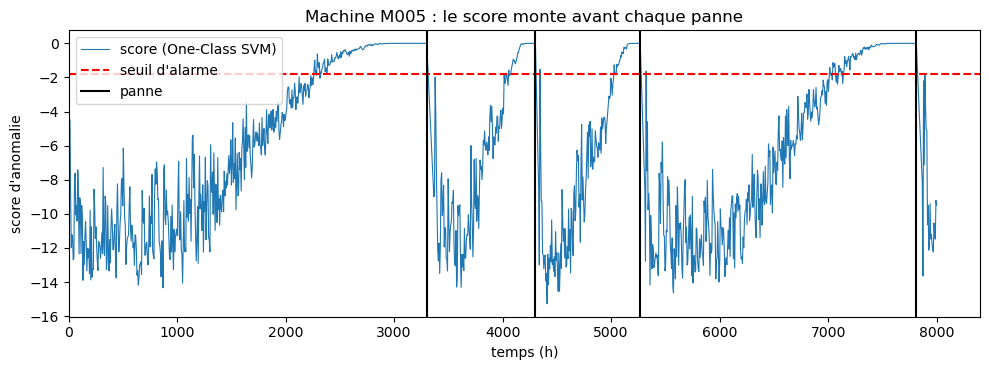

In [18]:
best = "One-Class SVM"
m = test[test.rul_h.notna()].groupby("machine_id").size().index[0]
g = test[(test.machine_id == m)]
thr = cal.loc[cal.age_h < HEALTHY_H, f"score_{best}"].quantile(0.99)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(g.time_h, g[f"score_{best}"], lw=0.8, label=f"score ({best})")
ax.axhline(thr, color="red", ls="--", label="seuil d'alarme")
for _, r in g[g.rul_h.notna()].groupby("cycle_id").tail(1).iterrows():
    ax.axvline(r.time_h, color="black", lw=1.5)
ax.axvline(-100, color="black", lw=1.5, label="panne")
ax.set_xlim(left=0); ax.set_xlabel("temps (h)"); ax.set_ylabel("score d'anomalie")
ax.set_title(f"Machine {m} : le score monte avant chaque panne"); ax.legend()
plt.tight_layout(); plt.savefig(ROOT / "reports/figures/anomalies_exemple_machine.png", dpi=150); plt.show()

## 7. Sauvegarde des résultats

In [19]:
final = res.join(summary)
final.to_csv(ROOT / "reports/tables/resultats_anomalies.csv")
final

,ROC-AUC,PR-AUC,seuil,pannes détectées,taux de détection,délai médian (h),fausses alarmes (sain)
modèle,,,,,,,
Isolation Forest,0.941,0.314,0.522,43/44,0.977,1038.0,0.0088
One-Class SVM,0.983,0.576,-1.796,43/44,0.977,667.0,0.0018
Autoencodeur,0.955,0.391,2.200,43/44,0.977,592.0,0.0000
